# Non-Gaussian dust through the Gaussian sampler

[`02_sampling_gaussian_dust.ipynb`](02_sampling_gaussian_dust.ipynb) ran the Gaussian dust sampler on data whose dust really was Gaussian. This notebook asks the next question: **how much does the recovered tensor-to-scalar ratio $r$ suffer when the dust in the data is not Gaussian, but the sampler still assumes it is?**

Two data sets are simulated and sampled with the same Gaussian posterior:

| Data set | Dust at 353 GHz | CMB and noise |
|---|---|---|
| **PySM** | The PySM `d9` model of the real sky on the BICEP/Keck field (`dust_model = "pysm"`): non-Gaussian, and not uniform across the patch | same seed |
| **Gaussian** | A Gaussian random field whose EE and BB power laws are fitted to the PySM dust | same seed |

Because the seed is shared, the CMB realization and the noise realization are identical in the two data sets. The Gaussian dust is matched to the PySM dust in power, so the two data sets differ only in how that dust power is arranged on the sky. Any difference in the recovered $r$ is then down to the structure of the dust, not its brightness.

In both cases the dust is scaled across the 95, 150 and 220 GHz channels with the same modified blackbody the sampler assumes, so no frequency-scaling mismatch is being tested here.


In [1]:
import contextlib
import io
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import NullFormatter, ScalarFormatter
from scipy.stats import gaussian_kde
from cmb_lensing.util import gen_ell_grid, get_fourier_weights
from cmb_lensing.mcmc_diagnostics import autocorrelation, integrated_autocorrelation_time
from cmb_lensing.chain_analysis import product_moments, product_pdf
from cmb_scattering.simulate_dust import DUST_PIVOT_ELL, GAUSSIAN_DUST, PYSM_DUST, simulate_data
from cmb_scattering.sampler import PARAM_BOUNDS, PARAM_ORDER, sample_gaussian_posterior

#importing cmb_lensing.chain_analysis switches matplotlib to the file-only Agg backend,
#so switch back to drawing figures in the notebook
%matplotlib inline

nside = 128
theta_pix = 20.0
uk_arcmin = 3.0
map_seed = 0
r_true = 0.03
frequency_exponent_true = 1.49

#the PySM data set: the dust amplitudes and knees are not inputs of this simulation
pysm_sim = simulate_data(nside, theta_pix, map_seed, r_true, frequency_exponent_true,
                         uk_arcmin = uk_arcmin, dust_model = PYSM_DUST)

## A Gaussian dust model matched to the PySM dust

To give the Gaussian data set the same dust power, a power law $D_\ell = A\,(\ell/80)^{\alpha}$ is fitted to the PySM dust's EE and BB spectra. The spectrum is averaged in logarithmic bins of $\ell$ and a straight line is fitted in log-log space.


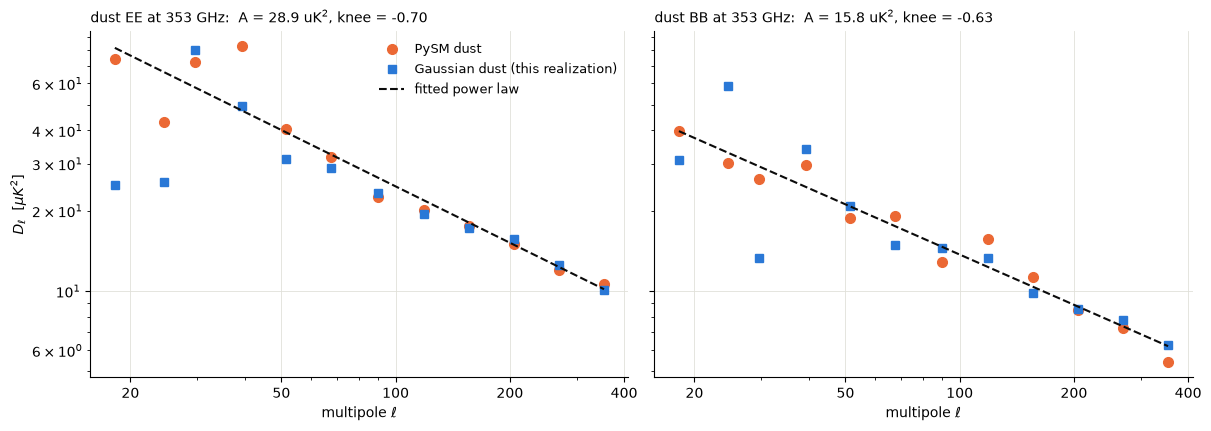

   dust_amplitude_ee = 28.87
        dust_knee_ee = -0.7018
   dust_amplitude_bb = 15.76
        dust_knee_bb = -0.6253


In [2]:
#multipole range and number of logarithmic bins of the power-law fit
FIT_ELL_MIN = 15
FIT_ELL_MAX = 400
FIT_NUM_BINS = 12
#multipoles labelled on the x-axis of the spectrum plot
SPECTRUM_ELL_TICKS = [20, 50, 100, 200, 400]

INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
GAUSSIAN_COLOR = "#2a78d6"
PYSM_COLOR = "#eb6834"

ell_grid, pix_width = gen_ell_grid(nside, theta_pix)
ell_grid = np.asarray(ell_grid)
#weight of each rfft2 mode in an average over the full Fourier plane: 2 in the bulk, whose
#modes stand for themselves and their conjugate, and 1 in the two self-conjugate columns,
#where the array already holds both
fourier_weights = np.broadcast_to(np.real(np.asarray(get_fourier_weights(ell_grid.shape))),
                                  ell_grid.shape)

def style_axis(ax):
    ax.grid(color = GRID, lw = 0.6)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

def binned_dl(fourier_matrix):
    #(bin centres, D_ell in uK^2) of one field component: the average over the Fourier
    #plane in logarithmic ell bins, each rfft2 mode weighted by fourier_weights
    cl_per_mode = np.abs(np.asarray(fourier_matrix))**2 / nside**2 * pix_width**2
    dl_per_mode = ell_grid * (ell_grid + 1) * cl_per_mode / (2 * np.pi)
    edges = np.geomspace(FIT_ELL_MIN, FIT_ELL_MAX, FIT_NUM_BINS + 1)
    centres, values = [], []
    for low, high in zip(edges[:-1], edges[1:]):
        in_bin = (ell_grid >= low) & (ell_grid < high)
        if in_bin.any():
            weights = fourier_weights[in_bin]
            centres.append(np.average(ell_grid[in_bin], weights = weights))
            values.append(np.average(dl_per_mode[in_bin], weights = weights))
    return np.array(centres), np.array(values)

def fit_power_law(fourier_matrix):
    #(amplitude at ell = 80, knee) of the power law fitted to the binned D_ell
    centres, values = binned_dl(fourier_matrix)
    knee, log_amplitude = np.polyfit(np.log(centres / DUST_PIVOT_ELL), np.log(values), 1)
    return float(np.exp(log_amplitude)), float(knee)

pysm_dust = pysm_sim["dust_field"]
dust_amplitude_ee, dust_knee_ee = fit_power_law(pysm_dust.polar_matrix_1)
dust_amplitude_bb, dust_knee_bb = fit_power_law(pysm_dust.polar_matrix_2)
matched_dust_params = {"dust_amplitude_ee": dust_amplitude_ee, "dust_knee_ee": dust_knee_ee,
                       "dust_amplitude_bb": dust_amplitude_bb, "dust_knee_bb": dust_knee_bb}

#the Gaussian data set: same seed, so the same CMB and the same noise
gaussian_sim = simulate_data(nside, theta_pix, map_seed, r_true, frequency_exponent_true,
                             uk_arcmin = uk_arcmin, dust_model = GAUSSIAN_DUST,
                             **matched_dust_params)

fig, axes = plt.subplots(1, 2, figsize = (12, 4.2), sharey = True, constrained_layout = True)
components = (("EE", "polar_matrix_1", dust_amplitude_ee, dust_knee_ee),
              ("BB", "polar_matrix_2", dust_amplitude_bb, dust_knee_bb))
for ax, (label, matrix_name, amplitude, knee) in zip(axes, components):
    centres, pysm_values = binned_dl(getattr(pysm_dust, matrix_name))
    _, gaussian_values = binned_dl(getattr(gaussian_sim["dust_field"], matrix_name))
    ax.loglog(centres, pysm_values, "o", color = PYSM_COLOR, ms = 7, label = "PySM dust")
    ax.loglog(centres, gaussian_values, "s", color = GAUSSIAN_COLOR, ms = 6,
              label = "Gaussian dust (this realization)")
    ax.loglog(centres, amplitude * (centres / DUST_PIVOT_ELL)**knee, color = INK, lw = 1.5,
              ls = "--", label = "fitted power law")
    ax.set_title(f"dust {label} at 353 GHz:  A = {amplitude:.1f} uK$^2$, knee = {knee:.2f}",
                 loc = "left", fontsize = 10)
    ax.set_xlabel(r"multipole $\ell$")
    #plain numbers at a few chosen multipoles in place of the default 2 x 10^1 style labels
    ax.set_xticks(SPECTRUM_ELL_TICKS)
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.xaxis.set_minor_formatter(NullFormatter())
    style_axis(ax)
axes[0].set_ylabel(r"$D_\ell$  [$\mu K^2$]")
axes[0].legend(frameon = False, fontsize = 9)
plt.show()

for name, value in matched_dust_params.items():
    print(f"{name:>20} = {value:.4g}")

The PySM dust on this patch is brighter than BK18's $A_d = 4.4\ \mu K^2$, because the 43 degree patch is far larger than the BICEP/Keck field and takes in brighter sky.

## Same CMB and noise, different dust

The two data sets must share everything except the dust. The check below compares the CMB fields directly, and recovers each data set's noise by subtracting its own noise-free model.


In [3]:
from cmb_scattering.simulate_dust import data_model

def noise_of(sim):
    #the noise realization of a data set: the data minus its noise-free model
    model = data_model(sim["cmb_field"], sim["dust_field"], sim["frequency_scaling"],
                       sim["mask"], sim["beam"])
    return sim["data"] - model

def max_difference(field_a, field_b):
    return max(float(np.max(np.abs(np.asarray(field_a.polar_matrix_1 - field_b.polar_matrix_1)))),
               float(np.max(np.abs(np.asarray(field_a.polar_matrix_2 - field_b.polar_matrix_2)))))

noise_scale = float(np.std(np.asarray(noise_of(gaussian_sim).polar_matrix_2)))
print("largest CMB difference between the data sets:  ",
      max_difference(pysm_sim["cmb_field"], gaussian_sim["cmb_field"]))
print("largest noise difference between the data sets:",
      f"{max_difference(noise_of(pysm_sim), noise_of(gaussian_sim)):.2e}",
      f"(noise modes have a typical size of {noise_scale:.2f})")

largest CMB difference between the data sets:   0.0
largest noise difference between the data sets: 9.17e-13 (noise modes have a typical size of 19.21)


The CMB fields are identical, and the noise fields agree to rounding error. Now the dust itself. The B-mode dust maps at 353 GHz are drawn on one colour scale.


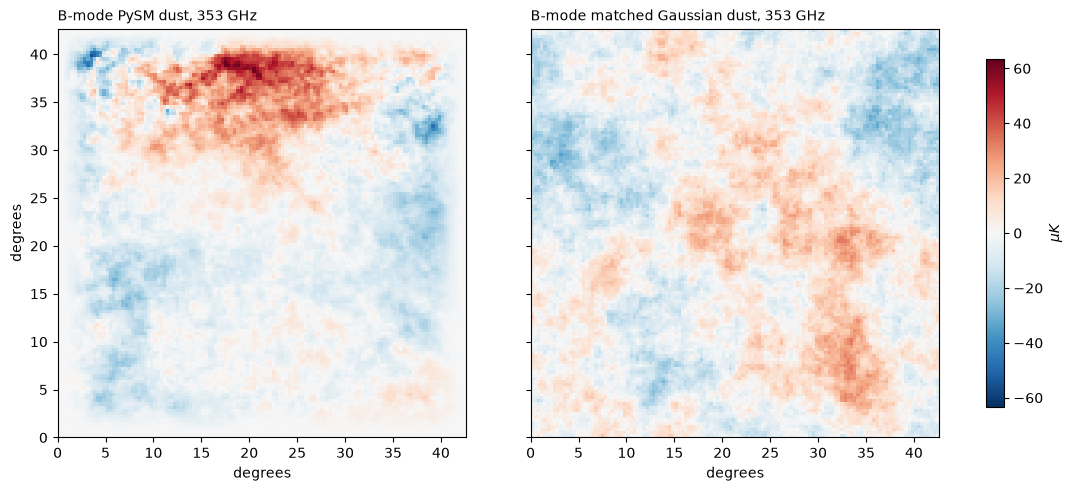

In [4]:
ARCMIN_PER_DEGREE = 60
width_deg = nside * theta_pix / ARCMIN_PER_DEGREE
extent = (0, width_deg, 0, width_deg)

def to_map(matrix):
    #real-space map (uK) of an rfft2 matrix
    return np.fft.irfft2(np.asarray(matrix))

dust_maps = {"PySM dust": to_map(pysm_dust.polar_matrix_2),
             "matched Gaussian dust": to_map(gaussian_sim["dust_field"].polar_matrix_2)}
limit = max(np.abs(values).max() for values in dust_maps.values())

fig, axes = plt.subplots(1, 2, figsize = (11, 4.8), sharey = True, constrained_layout = True)
for ax, (title, values) in zip(axes, dust_maps.items()):
    image = ax.imshow(values, origin = "lower", extent = extent, cmap = "RdBu_r",
                      vmin = -limit, vmax = limit)
    ax.set_title(f"B-mode {title}, 353 GHz", loc = "left", fontsize = 10)
    ax.set_xlabel("degrees")
axes[0].set_ylabel("degrees")
fig.colorbar(image, ax = axes, shrink = 0.85, label = r"$\mu K$")
plt.show()

The two maps have the same power spectrum by construction and look nothing alike. The Gaussian dust is statistically the same everywhere. The PySM dust is concentrated toward one side of the patch, where the sky is closer to the Galactic plane, and fades to zero at the edges because of the taper that makes it periodic. The sampler's dust model describes only the first kind of field.

## Running the Gaussian sampler on both

Both chains use the same sampler seed, the same starting point (the true $r$ and frequency exponent, and the fitted dust parameters) and the same proposal widths, hand-tuned for this brighter dust. The prior range of the two dust knees is widened from the sampler's default $(-1, 0)$ to $(-2, 0)$, because the PySM chain otherwise runs into the lower edge.


In [5]:
num_iterations = 2000
chain_seed = 1
#iterations dropped from the start of each chain
burn_in = 300

param_init = dict(matched_dust_params, r = r_true, frequency_exponent = frequency_exponent_true)
#width of each parameter's Gaussian Metropolis proposal, hand-tuned for this dust level
proposal_widths = {
    "dust_amplitude_ee": 0.8,
    "dust_amplitude_bb": 0.4,
    "dust_knee_ee": 0.02,
    "dust_knee_bb": 0.02,
    "r": 0.008,
    "frequency_exponent": 0.002,
}
WIDE_KNEE_BOUNDS = (-2.0, 0.0)
param_bounds = dict(PARAM_BOUNDS, dust_knee_ee = WIDE_KNEE_BOUNDS, dust_knee_bb = WIDE_KNEE_BOUNDS)

sims = {"Gaussian": gaussian_sim, "PySM": pysm_sim}
colors = {"Gaussian": GAUSSIAN_COLOR, "PySM": PYSM_COLOR}
sample_histories, acceptance_rates, logposterior_values = {}, {}, {}
for label, sim in sims.items():
    #capture the per-iteration acceptance printout
    with contextlib.redirect_stdout(io.StringIO()):
        sample_histories[label], acceptance_rates[label], logposterior_values[label] = sample_gaussian_posterior(
            sim["data"], sim["noise_covariance"], sim["scalar_covariance"],
            sim["tensor_covariance"], sim["mask"], sim["beam"], param_init,
            proposal_widths = proposal_widths, param_bounds = param_bounds,
            num_iterations = num_iterations, seed = chain_seed,
            frequencies = sim["frequencies"])

print(f"{'acceptance rate':>20}  " + "  ".join(f"{label:>9}" for label in sims))
for name in PARAM_ORDER:
    print(f"{name:>20}  " + "  ".join(f"{acceptance_rates[label][name]:9.2f}" for label in sims))

     acceptance rate   Gaussian       PySM
   dust_amplitude_ee       0.41       0.52
   dust_amplitude_bb       0.44       0.54
        dust_knee_ee       0.38       0.39
        dust_knee_bb       0.38       0.39
                   r       0.45       0.47
  frequency_exponent       0.39       0.37


## The recovered r

The trace of $r$ in both chains, then its posterior from each.


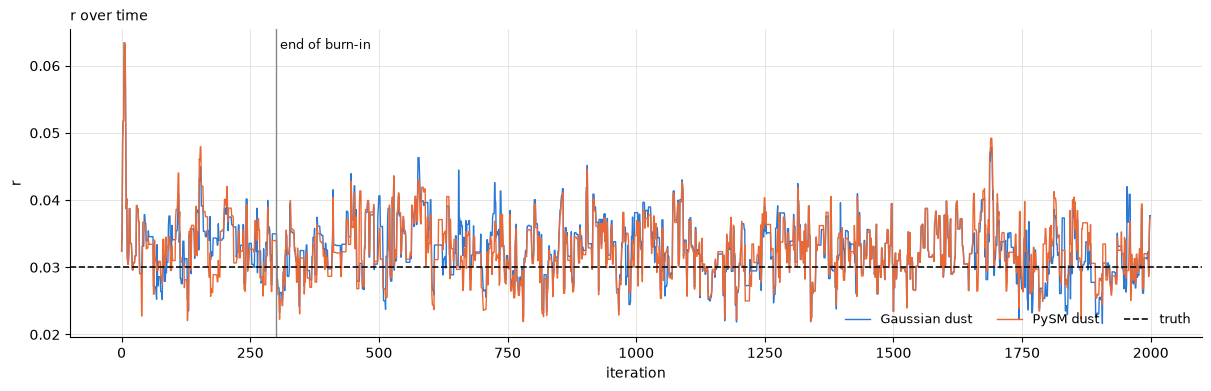

In [6]:
fig, ax = plt.subplots(figsize = (12, 3.8), constrained_layout = True)
for label in sims:
    ax.plot(sample_histories[label]["r"], color = colors[label], lw = 1.0, label = f"{label} dust")
ax.axhline(r_true, color = INK, lw = 1.2, ls = "--", label = "truth")
ax.axvline(burn_in, color = MUTED, lw = 1)
ax.text(burn_in, 0.97, " end of burn-in", color = INK, fontsize = 9, va = "top",
        transform = ax.get_xaxis_transform())
ax.set_xlabel("iteration")
ax.set_ylabel("r")
ax.set_title("r over time", loc = "left", fontsize = 10)
style_axis(ax)
ax.legend(frameon = False, fontsize = 9, ncols = 3, loc = "lower right")
plt.show()

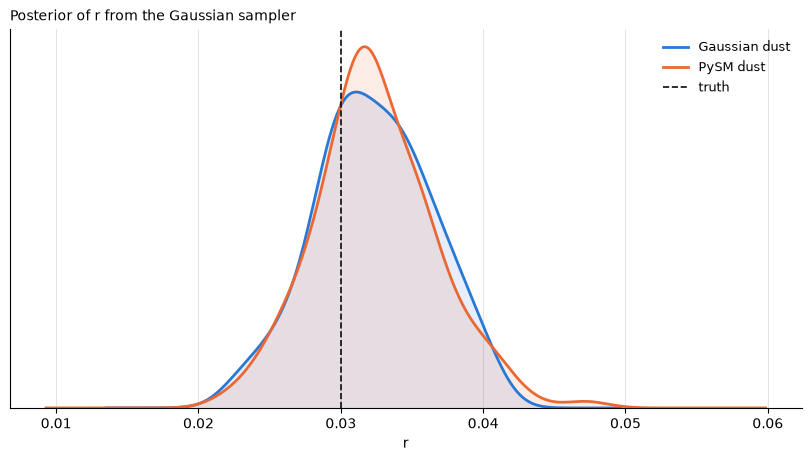

  data set    mean r       std      bias   z-score     IAT  thinned samples
  Gaussian    0.0323    0.0043   +0.0023     +0.53    15.9              114
      PySM    0.0324    0.0045   +0.0024     +0.55    12.9              142

shift in r from swapping Gaussian dust for PySM dust: +0.0001 (+0.03 of the Gaussian-dust std)
ratio of the posterior widths, PySM / Gaussian: 1.03


In [ ]:
KDE_GRID_POINTS = 400
#how far past the samples' range the density is drawn, as a fraction of that range
KDE_GRID_PADDING = 0.5

def chain_summary(chain, truth = None):
    #IAT, thinned samples, and the KDE's grid, density, mean and std for one parameter chain
    iat = integrated_autocorrelation_time(autocorrelation(chain))
    samples = chain[::max(int(iat), 1)]
    low, high = samples.min(), samples.max()
    if truth is not None:
        low, high = min(low, truth), max(high, truth)
    padding = KDE_GRID_PADDING * (high - low)
    grid = np.linspace(low - padding, high + padding, KDE_GRID_POINTS)
    density = product_pdf([gaussian_kde(samples)(grid)], grid)
    mean, std = product_moments(density, grid)
    return {"iat": iat, "num_samples": len(samples), "grid": grid, "density": density,
            "mean": mean, "std": std}

r_summary = {label: chain_summary(sample_histories[label]["r"][burn_in:], r_true)
             for label in sims}

fig, ax = plt.subplots(figsize = (8, 4.5), constrained_layout = True)
for label in sims:
    summary = r_summary[label]
    ax.plot(summary["grid"], summary["density"], color = colors[label], lw = 2, label = f"{label} dust")
    ax.fill_between(summary["grid"], summary["density"], color = colors[label], alpha = 0.12, lw = 0)
ax.axvline(r_true, color = INK, lw = 1.2, ls = "--", label = "truth")
ax.set_xlabel("r")
ax.set_yticks([])
ax.set_ylim(bottom = 0)
ax.set_title("Posterior of r from the Gaussian sampler", loc = "left", fontsize = 10)
style_axis(ax)
ax.legend(frameon = False, fontsize = 9)
plt.show()

print(f"{'data set':>10}  {'mean r':>8}  {'std':>8}  {'bias':>8}  {'z-score':>8}  {'IAT':>6}  {'thinned samples':>15}")
for label in sims:
    summary = r_summary[label]
    bias = summary["mean"] - r_true
    print(f"{label:>10}  {summary['mean']:8.4f}  {summary['std']:8.4f}  {bias:+8.4f}  "
          f"{bias / summary['std']:+8.2f}  {summary['iat']:6.1f}  {summary['num_samples']:15d}")

shift = r_summary["PySM"]["mean"] - r_summary["Gaussian"]["mean"]
print(f"\nshift in r from swapping Gaussian dust for PySM dust: {shift:+.4f} "
      f"({shift / r_summary['Gaussian']['std']:+.2f} of the Gaussian-dust std)")
print(f"ratio of the posterior widths, PySM / Gaussian: "
      f"{r_summary['PySM']['std'] / r_summary['Gaussian']['std']:.2f}")

The bias is the posterior mean minus the true $r = 0.03$, and the z-score is that bias in units of the posterior standard deviation. The last two lines compare the data sets directly: because the CMB and the noise are shared, the shift isolates what changing the dust does.

## What the sampler made of the dust

The Gaussian sampler still fits a power-law dust model to the PySM data. The table gives the posterior mean and standard deviation of each dust parameter in both chains, next to the values fitted to the PySM spectrum above.


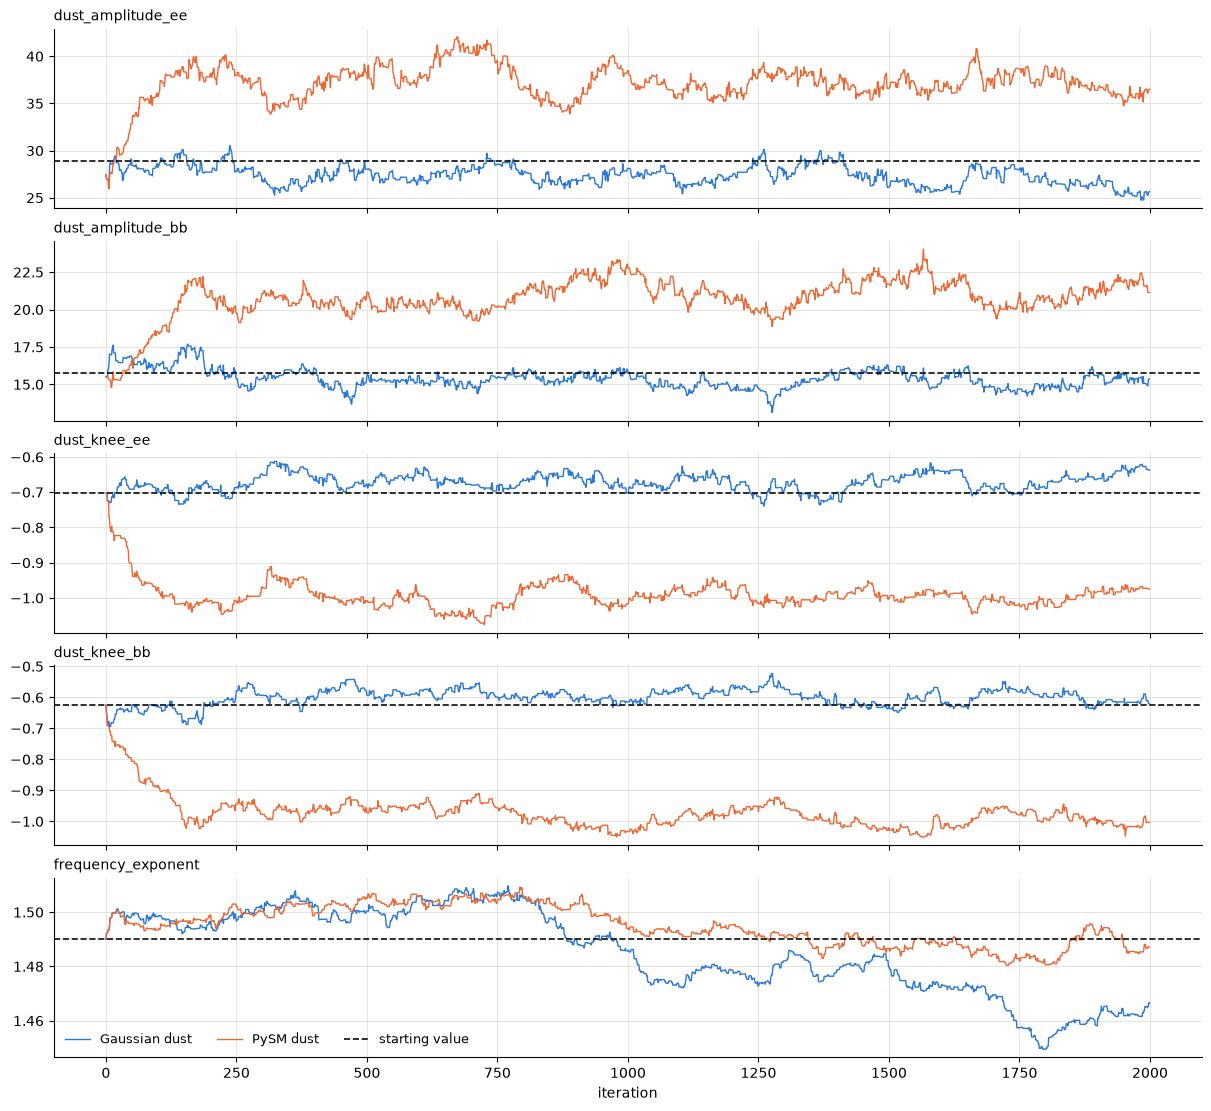

           parameter     start       Gaussian dust           PySM dust    IAT (G / P)
   dust_amplitude_ee    28.870     27.172 +/- 1.010     37.407 +/- 1.635     45 / 44
   dust_amplitude_bb    15.759     15.211 +/- 0.489     21.010 +/- 1.070     46 / 57
        dust_knee_ee    -0.702     -0.669 +/- 0.029     -0.997 +/- 0.031     41 / 39
        dust_knee_bb    -0.625     -0.596 +/- 0.022     -0.983 +/- 0.030     51 / 69
  frequency_exponent     1.490      1.489 +/- 0.019      1.497 +/- 0.007    469 / 435


In [8]:
dust_names = [name for name in PARAM_ORDER if name != "r"]
dust_summary = {label: {name: chain_summary(sample_histories[label][name][burn_in:])
                        for name in dust_names} for label in sims}

fig, axes = plt.subplots(len(dust_names), 1, figsize = (12, 2.2 * len(dust_names)),
                         sharex = True, constrained_layout = True)
for ax, name in zip(axes, dust_names):
    for label in sims:
        ax.plot(sample_histories[label][name], color = colors[label], lw = 1.0,
                label = f"{label} dust")
    ax.axhline(param_init[name], color = INK, lw = 1.2, ls = "--", label = "starting value")
    ax.set_title(name, loc = "left", fontsize = 10)
    style_axis(ax)
axes[-1].legend(frameon = False, fontsize = 9, ncols = 3, loc = "lower left")
axes[-1].set_xlabel("iteration")
plt.show()

print(f"{'parameter':>20}  {'start':>8}  {'Gaussian dust':>18}  {'PySM dust':>18}  {'IAT (G / P)':>13}")
for name in dust_names:
    gaussian, pysm = dust_summary["Gaussian"][name], dust_summary["PySM"][name]
    print(f"{name:>20}  {param_init[name]:8.3f}  "
          f"{gaussian['mean']:9.3f} +/- {gaussian['std']:.3f}  "
          f"{pysm['mean']:9.3f} +/- {pysm['std']:.3f}  "
          f"{gaussian['iat']:5.0f} / {pysm['iat']:.0f}")

## What this shows

**On this map, swapping Gaussian dust for PySM dust did not change the recovered $r$.**

- With Gaussian dust the sampler gives $r = 0.0323 \pm 0.0043$, and with PySM dust $r = 0.0324 \pm 0.0045$, against a truth of 0.03. Both are about half a standard deviation high.
- The shift between the two is $+0.0001$, or 0.03 of a standard deviation. The posterior widths differ by 3 %, which is within what a KDE of just over 100 thinned samples can resolve.
- The two z-scores are not independent checks. The data sets share their CMB and noise, so the common half-sigma offset is most likely the same fluctuation seen twice.

The dust parameters tell a different story. Fitting its power-law model to the PySM dust, the sampler settles on dust that is brighter and much steeper (knees near $-1.0$) than the binned fit used to build the Gaussian data set (knees of $-0.70$ for EE and $-0.63$ for BB). The Gaussian chain, by contrast, stays within two standard deviations of the values it was simulated with. Two things drive the steep fit, and both are properties of this simulation, not of the sky: the PySM dust has no power above the grid's Nyquist multipole of 540 while the grid's corner modes extend to 764, and the interpolation onto the flat grid smooths the smallest scales. The sampler's default prior on the knees, $(-1, 0)$, would have been hit, which is why it was widened here.

So the Gaussian model is visibly wrong about this dust, and $r$ comes out the same anyway.

### Why r is probably insensitive here

A likely reason, not something this notebook demonstrates: with three channels and a dust frequency scaling that the sampler knows exactly, the dust is separated from the CMB by its colour, not by its statistics. Each Fourier mode of the dust is measured directly from how the data change between 95 and 220 GHz, and the Gaussian dust prior has little left to decide. Non-Gaussianity should matter far more when that handle is weak or wrong.

### What this does not establish

- **One map and one chain.** A bias smaller than the posterior width cannot be seen here. That needs many CMB and noise seeds per dust model.
- **One dust realization.** The PySM dust is the same on every call, so more seeds average over CMB and noise only. A different dust field means a different patch of sky.
- **The easy case for frequency scaling.** The dust follows the sampler's modified blackbody exactly. Real dust has a spectral index and temperature that vary across the sky, which PySM's `d10` model includes and this test deliberately leaves out.
- **The frequency exponent has not converged.** Its autocorrelation time is around 450 iterations in both chains, so each holds only a few independent samples of it.
- **Projection choices.** The edge taper, the longitude / latitude layout of a 43 degree patch and the band limit all shape the PySM dust on this grid.

The natural next steps are the same comparison over many seeds, and then the harder versions: PySM dust with its own spatially varying frequency scaling, fewer or noisier channels, and a smaller patch closer to the real BICEP/Keck field.
